In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from scipy.stats import randint, uniform, loguniform
import tensorflow as tf
from tensorflow.keras import layers,regularizers
import joblib


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ziya07/ev-energy-consumption-dataset")

print("Path to dataset files:", path)

100%|██████████| 630k/630k [00:00<00:00, 751kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ziya07/ev-energy-consumption-dataset/versions/1


In [3]:
path="/root/.cache/kagglehub/datasets/ziya07/ev-energy-consumption-dataset/versions/1"
print(os.listdir(path))

['EV_Energy_Consumption_Dataset.csv']


In [4]:
csv_file = os.path.join(path, "EV_Energy_Consumption_Dataset.csv")
df = pd.read_csv(csv_file)
df.head()

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.507366,-2.773816,30.415148,378.091525,25.314786,2,1,1,6.879446,4,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,2024-01-01 00:01:00,48.612323,-0.796982,97.385534,392.718377,18.240755,1,2,1,-3.007212,4,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,2024-01-01 00:02:00,108.733320,0.253800,84.912600,398.993495,44.449145,1,1,3,0.029585,1,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,2024-01-01 00:03:00,38.579484,-2.111395,28.777904,358.128273,28.980155,1,2,2,8.271943,3,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,2024-01-01 00:04:00,57.172438,1.477883,29.740160,310.888162,33.184551,2,1,1,2.776814,2,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205


In [5]:
df.shape

(5000, 19)

In [6]:
df.columns

Index(['Vehicle_ID', 'Timestamp', 'Speed_kmh', 'Acceleration_ms2',
       'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C',
       'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Slope_%',
       'Weather_Condition', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms',
       'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km',
       'Energy_Consumption_kWh'],
      dtype='object')

In [7]:
df.describe()

,Vehicle_ID,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,1505.701200,59.312952,-0.019885,60.214465,351.118306,27.510130,2.011000,1.999200,2.010800,2.504690,2.48340,17.312654,55.302173,7.505087,31.503390,1854.719760,24.994042,8.437983
std,290.836902,34.517605,1.724287,23.128262,28.968372,10.015385,0.810068,0.808536,0.812167,4.360854,1.11372,13.005106,20.161289,4.325455,2.017357,373.685150,14.246454,2.184809
min,1000.000000,0.001396,-2.999683,20.020196,300.004812,10.003858,1.000000,1.000000,1.000000,-4.991079,1.00000,-4.995288,20.027119,0.000126,28.001891,1200.960317,0.107544,1.881426
25%,1253.000000,29.515400,-1.490240,40.088318,326.613439,18.884742,1.000000,1.000000,1.000000,-1.235653,1.00000,5.950476,37.970900,3.837738,29.772709,1531.417633,12.736568,6.771081
50%,1510.000000,58.646794,-0.043329,60.490283,351.510915,27.581710,2.000000,2.000000,2.000000,2.452368,2.00000,17.330798,55.650512,7.495373,31.484048,1865.006523,24.640458,8.455746
75%,1761.000000,89.030001,1.473887,80.409928,375.968140,35.920162,3.000000,3.000000,3.000000,6.366990,3.00000,28.624021,72.650838,11.291284,33.256528,2181.071491,37.562482,10.031938
max,1999.000000,119.946924,2.998039,99.993986,399.990098,44.985943,3.000000,3.000000,3.000000,9.998358,4.00000,39.998063,89.988891,14.999095,34.997829,2499.504564,49.993767,14.660528


In [8]:
df["Vehicle_ID"].value_counts()

,count
Vehicle_ID,
1663,14
1098,12
1038,12
1112,12
1957,12
...,...
1486,1
1809,1
1354,1


In [9]:
df[df["Vehicle_ID"]==1663]

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
18,1663,2024-01-01 00:18:00,81.914067,1.384074,81.205075,355.901089,24.328539,1,3,1,1.745343,3,26.324376,45.049775,5.797929,28.875462,1948.718166,22.447736,8.607422
258,1663,2024-01-01 04:18:00,11.447913,-0.984323,21.880194,317.662343,39.647490,1,1,1,-4.394814,3,35.649756,55.114858,12.674563,32.035893,1923.064531,22.995004,7.547332
695,1663,2024-01-01 11:35:00,95.130974,1.901268,66.494827,354.853899,36.076279,1,2,1,0.451402,3,-0.372684,73.388522,8.763724,33.536775,2333.319570,25.940164,10.085508
761,1663,2024-01-01 12:41:00,74.456854,1.466209,34.615585,377.909794,23.869818,2,2,3,-0.562674,4,-4.186053,30.387514,6.278200,31.252413,2026.701938,12.296084,8.790656
1309,1663,2024-01-01 21:49:00,66.844862,-0.758602,73.778030,329.752955,33.922470,1,1,1,5.184917,1,28.510731,78.845523,14.982819,31.323780,2201.749881,25.384132,9.234927
1624,1663,2024-01-02 03:04:00,87.629903,1.858731,85.067466,327.136902,13.197661,2,1,2,-0.414708,3,30.525340,22.836676,6.815251,33.179095,2194.633145,7.018837,7.495793
1891,1663,2024-01-02 07:31:00,48.328738,1.102197,97.521037,333.634064,34.933567,2,1,3,6.293215,3,6.815526,84.015724,5.998768,30.059234,2122.856441,41.464447,8.658582
3044,1663,2024-01-03 02:44:00,29.358607,-0.910352,48.221477,363.157811,10.666364,1,1,1,9.319393,1,16.325187,59.901166,0.706553,29.799043,2143.857672,40.180645,7.726610
3506,1663,2024-01-03 10:26:00,4.219110,0.186657,34.085363,301.952928,23.284881,1,3,2,1.586668,4,39.407150,30.892552,6.925512,31.110271,2492.099717,24.510598,6.065027
3782,1663,2024-01-03 15:02:00,62.184688,-2.973756,80.439925,368.144588,29.748105,1,1,1,6.413407,4,1.068254,62.142724,1.284159,32.707920,1386.589154,38.773610,9.577522


In [10]:
selected_cols = [
    "Vehicle_ID",
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
    "Energy_Consumption_kWh",
]

df_plot = df[selected_cols].copy()

df2 = df_plot.copy()
df2 = df2.drop(columns=["Vehicle_ID"])

valid_mask = (df2["Vehicle_Weight_kg"] > 0) & (df2["Distance_Travelled_km"] > 0)
df2 = df2.loc[valid_mask].copy()

df2["energy_per_km_per_kg"] = (
    df2["Energy_Consumption_kWh"]
    / (df2["Vehicle_Weight_kg"] * df2["Distance_Travelled_km"])
)

df2 = df2.drop(columns=["Energy_Consumption_kWh", "Distance_Travelled_km"])

df2.head()

,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Humidity_%,Wind_Speed_ms,Vehicle_Weight_kg,energy_per_km_per_kg
0,111.507366,-2.773816,30.415148,378.091525,25.314786,42.172533,7.829253,1822.967368,0.000319
1,48.612323,-0.796982,97.385534,392.718377,18.240755,57.018427,4.495572,2091.831914,0.003338
2,108.733320,0.253800,84.912600,398.993495,44.449145,69.028911,5.144489,1816.702497,0.000158
3,38.579484,-2.111395,28.777904,358.128273,28.980155,86.638349,4.518283,1283.102642,0.001086
4,57.172438,1.477883,29.740160,310.888162,33.184551,27.189185,4.263406,2160.350788,0.000537


In [11]:
df2.isnull().sum()

,0
Speed_kmh,0
Acceleration_ms2,0
Battery_State_%,0
Battery_Voltage_V,0
Battery_Temperature_C,0
Humidity_%,0
Wind_Speed_ms,0
Vehicle_Weight_kg,0
energy_per_km_per_kg,0


En observant la plage de voltage des voitures electriques on remarque que le min et le max ne sont pas très eloignés et que l'ecart type est à peine de 20V donc on peut faire raisonnablement l'hypothèse qu 'il s'agit de batteries avec globalement les mêmes caractéristiques et considérer ce dataset comme une mesure sur une seule batterie

In [12]:
df2

,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Humidity_%,Wind_Speed_ms,Vehicle_Weight_kg,energy_per_km_per_kg
0,111.507366,-2.773816,30.415148,378.091525,25.314786,42.172533,7.829253,1822.967368,0.000319
1,48.612323,-0.796982,97.385534,392.718377,18.240755,57.018427,4.495572,2091.831914,0.003338
2,108.733320,0.253800,84.912600,398.993495,44.449145,69.028911,5.144489,1816.702497,0.000158
3,38.579484,-2.111395,28.777904,358.128273,28.980155,86.638349,4.518283,1283.102642,0.001086
4,57.172438,1.477883,29.740160,310.888162,33.184551,27.189185,4.263406,2160.350788,0.000537
...,...,...,...,...,...,...,...,...,...
4995,60.036619,-0.685606,78.360306,355.284001,23.338767,73.356245,13.936821,1796.093041,0.000119
4996,107.291944,1.674625,68.163963,375.453798,19.056652,78.446046,12.197087,2095.099662,0.000608
4997,110.384512,1.348736,72.918142,303.834905,28.155775,78.251840,1.595182,2328.330539,0.000696
4998,6.618791,-2.642843,91.904887,302.708365,31.781034,74.929797,13.503355,1274.506744,0.000134


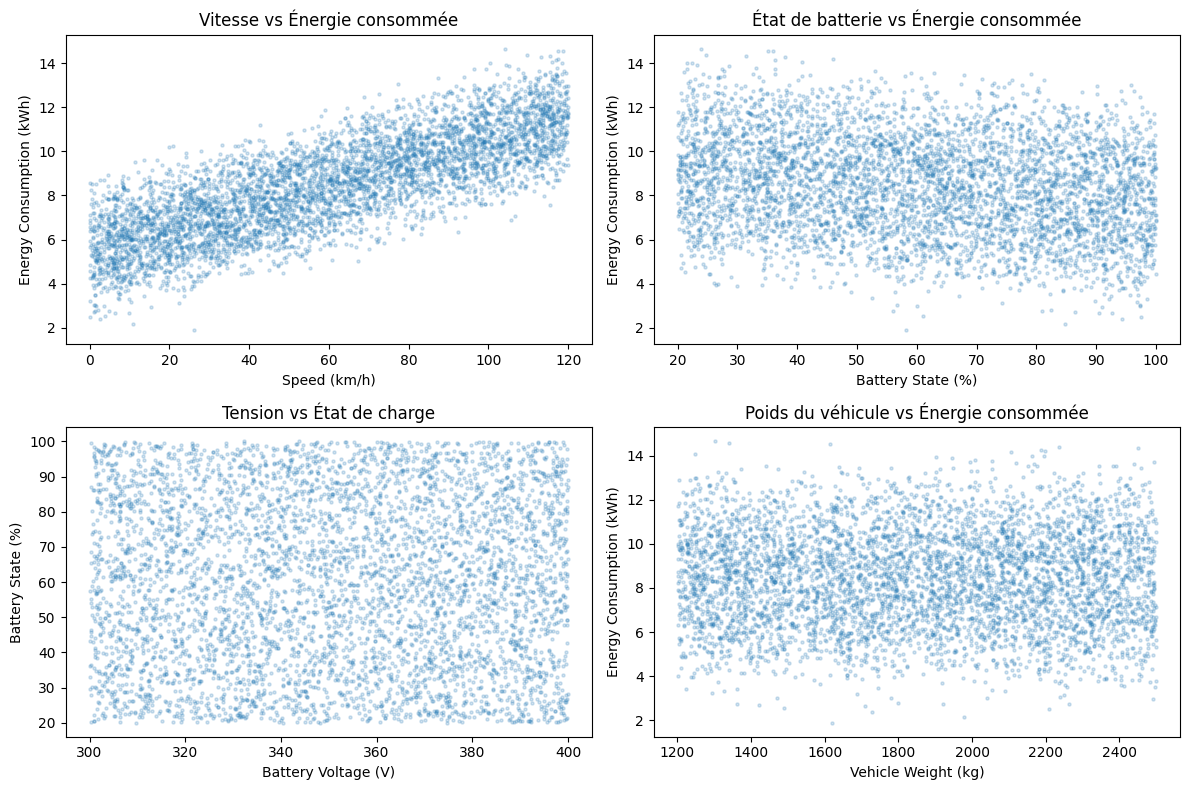

In [13]:
fig,axe=plt.subplots(nrows=2,ncols=2,figsize=(12,8))
axe[0][0].scatter(df_plot["Speed_kmh"],df_plot["Energy_Consumption_kWh"],alpha=0.2,s=5)
axe[0, 0].set_xlabel("Speed (km/h)")
axe[0, 0].set_ylabel("Energy Consumption (kWh)")
axe[0, 0].set_title("Vitesse vs Énergie consommée")
axe[0][1].scatter(df_plot["Battery_State_%"],df_plot["Energy_Consumption_kWh"],alpha=0.2,s=5)
axe[0, 1].set_xlabel("Battery State (%)")
axe[0, 1].set_ylabel("Energy Consumption (kWh)")
axe[0, 1].set_title("État de batterie vs Énergie consommée")
axe[1][0].scatter(df_plot["Battery_Voltage_V"],df_plot["Battery_State_%"],alpha=0.2,s=5)
axe[1, 0].set_xlabel("Battery Voltage (V)")
axe[1, 0].set_ylabel("Battery State (%)")
axe[1, 0].set_title("Tension vs État de charge")
axe[1][1].scatter(df_plot["Vehicle_Weight_kg"],df_plot["Energy_Consumption_kWh"],alpha=0.2,s=5)
axe[1, 1].set_xlabel("Vehicle Weight (kg)")
axe[1, 1].set_ylabel("Energy Consumption (kWh)")
axe[1, 1].set_title("Poids du véhicule vs Énergie consommée")
plt.tight_layout()


In [14]:
df2["Vehicle_Weight_kg"]

,Vehicle_Weight_kg
0,1822.967368
1,2091.831914
2,1816.702497
3,1283.102642
4,2160.350788
...,...
4995,1796.093041
4996,2095.099662
4997,2328.330539
4998,1274.506744


In [15]:
df2.corr()

,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Humidity_%,Wind_Speed_ms,Vehicle_Weight_kg,energy_per_km_per_kg
Speed_kmh,1.000000,-0.009457,-0.017952,0.006938,-0.000814,-0.021977,0.019374,-0.007969,0.055235
Acceleration_ms2,-0.009457,1.000000,-0.001797,-0.021792,0.028008,-0.005849,-0.014339,0.011653,0.001356
Battery_State_%,-0.017952,-0.001797,1.000000,0.004830,-0.002700,0.006732,0.039525,0.012064,-0.035166
Battery_Voltage_V,0.006938,-0.021792,0.004830,1.000000,-0.003077,-0.001389,-0.016575,-0.031485,0.014633
Battery_Temperature_C,-0.000814,0.028008,-0.002700,-0.003077,1.000000,0.027001,-0.013980,-0.018502,0.000179
Humidity_%,-0.021977,-0.005849,0.006732,-0.001389,0.027001,1.000000,0.001224,-0.018957,0.007450
Wind_Speed_ms,0.019374,-0.014339,0.039525,-0.016575,-0.013980,0.001224,1.000000,0.004176,0.001965
Vehicle_Weight_kg,-0.007969,0.011653,0.012064,-0.031485,-0.018502,-0.018957,0.004176,1.000000,-0.084342
energy_per_km_per_kg,0.055235,0.001356,-0.035166,0.014633,0.000179,0.007450,0.001965,-0.084342,1.000000


<Axes: >

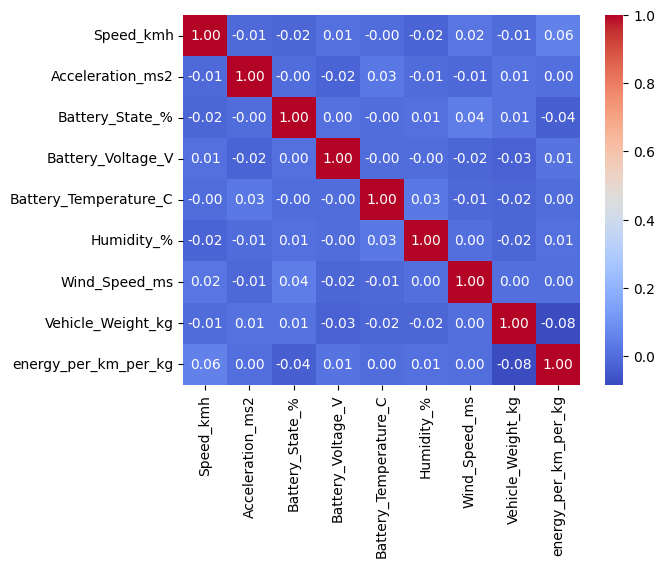

In [16]:
import seaborn as sns

sns.heatmap(df2.corr(),fmt=".2f",annot=True,cmap="coolwarm")

very few linear correlation

In [17]:
df2

,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Humidity_%,Wind_Speed_ms,Vehicle_Weight_kg,energy_per_km_per_kg
0,111.507366,-2.773816,30.415148,378.091525,25.314786,42.172533,7.829253,1822.967368,0.000319
1,48.612323,-0.796982,97.385534,392.718377,18.240755,57.018427,4.495572,2091.831914,0.003338
2,108.733320,0.253800,84.912600,398.993495,44.449145,69.028911,5.144489,1816.702497,0.000158
3,38.579484,-2.111395,28.777904,358.128273,28.980155,86.638349,4.518283,1283.102642,0.001086
4,57.172438,1.477883,29.740160,310.888162,33.184551,27.189185,4.263406,2160.350788,0.000537
...,...,...,...,...,...,...,...,...,...
4995,60.036619,-0.685606,78.360306,355.284001,23.338767,73.356245,13.936821,1796.093041,0.000119
4996,107.291944,1.674625,68.163963,375.453798,19.056652,78.446046,12.197087,2095.099662,0.000608
4997,110.384512,1.348736,72.918142,303.834905,28.155775,78.251840,1.595182,2328.330539,0.000696
4998,6.618791,-2.642843,91.904887,302.708365,31.781034,74.929797,13.503355,1274.506744,0.000134


In [18]:
df2["energy_per_km_per_kg"].describe()

,energy_per_km_per_kg
count,5000.000000
mean,0.000502
std,0.001871
min,0.000055
25%,0.000131
50%,0.000193
75%,0.000338
max,0.051868


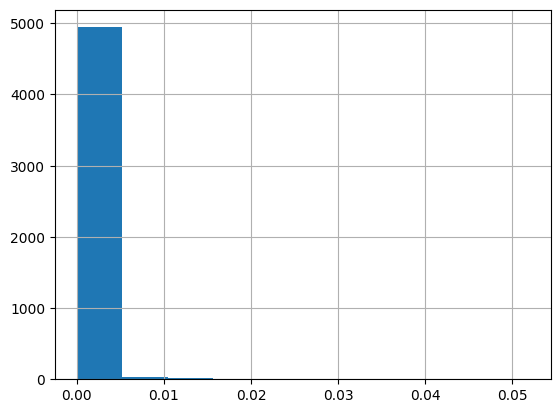

In [19]:
df2["energy_per_km_per_kg"].hist()
df2["log_energy_per_km_per_kg"]=np.log(df2["energy_per_km_per_kg"])


<Axes: >

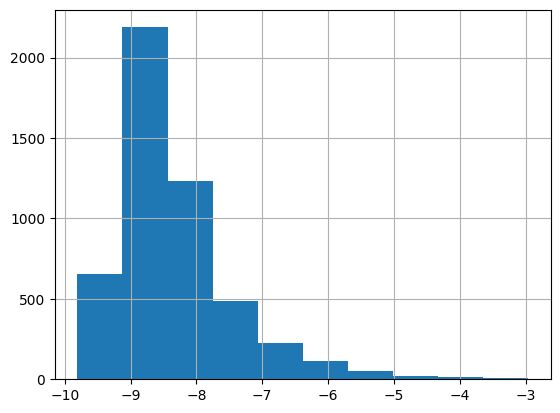

In [20]:
df2["log_energy_per_km_per_kg"].hist()

In [21]:
np.quantile(df2["log_energy_per_km_per_kg"],0.25)

np.float64(-8.937097748590345)

In [22]:
df2["log_energy_per_km_per_kg"].describe()

,log_energy_per_km_per_kg
count,5000.000000
mean,-8.341684
std,0.887379
min,-9.806723
25%,-8.937098
50%,-8.554691
75%,-7.993231
max,-2.959060


In [23]:
def IQR(df,feature):
    inf=np.quantile(df[f"{feature}"],0.25)
    sup=np.quantile(df[f"{feature}"],0.75)
    iqr=sup-inf
    borne_inf=inf-1.5*iqr
    borne_sup=sup+1.5*iqr
    return df[(df[f"{feature}"]>=borne_inf) & (df[f"{feature}"]<=borne_sup)]


<Axes: >

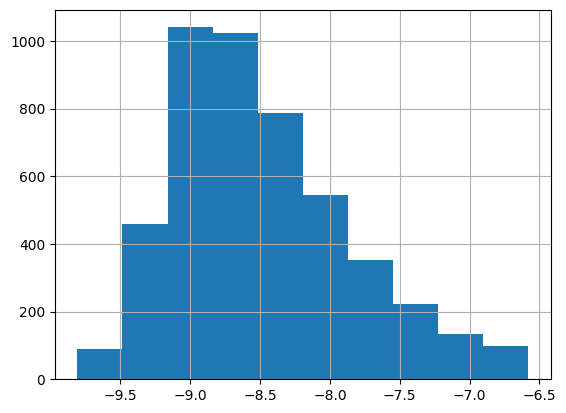

In [24]:
test=IQR(df2,"log_energy_per_km_per_kg")
test["log_energy_per_km_per_kg"].hist()

In [25]:
test.drop(columns="energy_per_km_per_kg",inplace=True)


/tmp/ipython-input-2135044695.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.drop(columns="energy_per_km_per_kg",inplace=True)


<Axes: >

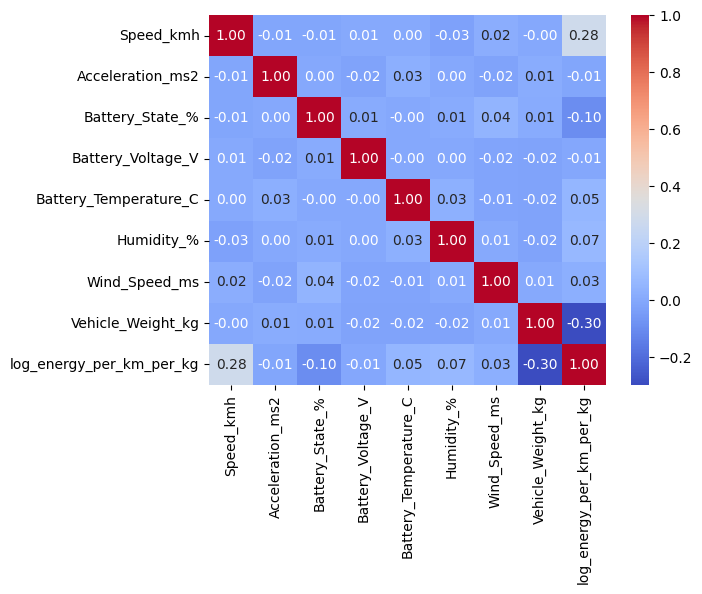

In [26]:
import seaborn as sns

sns.heatmap(test.corr(),fmt=".2f",annot=True,cmap="coolwarm")

In [27]:
test["log_energy_per_km_per_kg"].describe()

,log_energy_per_km_per_kg
count,4743.000000
mean,-8.483822
std,0.635868
min,-9.806723
25%,-8.956040
50%,-8.593676
75%,-8.101070
max,-6.580039


In [28]:
test.shape

(4743, 9)

In [30]:
X = test.drop(columns=["log_energy_per_km_per_kg"])
y = test["log_energy_per_km_per_kg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
preprocess_scale = ColumnTransformer(
    transformers=[("num", StandardScaler(), num_cols)],
    remainder="passthrough",
)
preprocess_passthrough = ColumnTransformer(
    transformers=[("num", "passthrough", num_cols)],
    remainder="passthrough",
)


In [31]:
models = {
    "RandomForest": {
        "pipeline": Pipeline(
            steps=[("prep", preprocess_passthrough), ("model", RandomForestRegressor(random_state=42, n_jobs=1))]
        ),
        "param_distributions": {
            "model__n_estimators": randint(200, 1200),
            "model__max_depth": [None] + list(range(3, 31)),
            "model__min_samples_leaf": randint(1, 11),
            "model__min_samples_split": randint(2, 21),
            "model__max_features": ["sqrt", "log2", None],
        },
    },
    "GradientBoosting": {
        "pipeline": Pipeline(
            steps=[("prep", preprocess_passthrough), ("model", GradientBoostingRegressor(random_state=42))]
        ),
        "param_distributions": {
            "model__n_estimators": randint(100, 1200),
            "model__learning_rate": loguniform(1e-3, 2e-1),
            "model__max_depth": randint(2, 8),
            "model__min_samples_leaf": randint(1, 11),
            "model__subsample": uniform(0.6, 0.4),  # 0.6 -> 1.0
        },
    },
    "Ridge": {
        "pipeline": Pipeline(steps=[("prep", preprocess_scale), ("model", Ridge(random_state=42))]),
        "param_distributions": {
            "model__alpha": loguniform(1e-4, 1e3),
        },
    },
    "ElasticNet": {
        "pipeline": Pipeline(steps=[("prep", preprocess_scale), ("model", ElasticNet(random_state=42, max_iter=20000))]),
        "param_distributions": {
            "model__alpha": loguniform(1e-4, 1e2),
            "model__l1_ratio": uniform(0.0, 1.0),
        },
    },
    "SVR_RBF": {
        "pipeline": Pipeline(steps=[("prep", preprocess_scale), ("model", SVR(kernel="rbf"))]),
        "param_distributions": {
            "model__C": loguniform(1e-2, 1e3),
            "model__gamma": loguniform(1e-4, 1e0),
            "model__epsilon": loguniform(1e-4, 1e-1),
        },
    },
    "KNN": {
        "pipeline": Pipeline(steps=[("prep", preprocess_scale), ("model", KNeighborsRegressor())]),
        "param_distributions": {
            "model__n_neighbors": randint(3, 61),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],  # Manhattan vs Euclidean
        },
    },
}

In [32]:
def eval_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MSE": mse,
        "RMSE": mse ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

In [33]:
results = {}          # metrics dictionary requested
best_estimators = {}  # keep best models if you want later

# You can tune these two knobs:
N_ITER = 10
CV = 3

for name, spec in models.items():
    search = RandomizedSearchCV(
        estimator=spec["pipeline"],
        param_distributions=spec["param_distributions"],
        n_iter=N_ITER,
        scoring="neg_root_mean_squared_error",  # optimize RMSE
        cv=CV,
        random_state=42,
        n_jobs=-1,
        verbose=2,
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    best_estimators[name] = best_model

    y_pred = best_model.predict(X_test)
    results[name] = eval_metrics(y_test, y_pred)
    results[name]["best_params"] = search.best_params_
    results[name]["cv_best_RMSE"] = -search.best_score_

# -----------------------------
# 4) Nicely view results
# -----------------------------
results_df = (
    pd.DataFrame(results)
    .T
    .sort_values(by="RMSE", ascending=True)
)

print(results_df[["RMSE", "MAE", "R2", "cv_best_RMSE"]])

# results is your dictionary of metrics
results

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Fitting 3 folds for each of 10 candidates, totalling 30 fits
                      RMSE       MAE        R2 cv_best_RMSE
ElasticNet        0.566837  0.449747  0.184418     0.577716
Ridge             0.566856   0.44974  0.184363     0.577717
RandomForest      0.572402  0.452578  0.168327     0.579167
GradientBoosting  0.572877  0.455737  0.166944     0.580993
KNN               0.576652  0.453871  0.155931     0.586278
SVR_RBF           0.599311  0.440024  0.088292     0.603157


{'RandomForest': {'MSE': 0.3276435935044618,
  'RMSE': 0.5724016015914541,
  'MAE': 0.4525777007318108,
  'R2': 0.16832720339248652,
  'best_params': {'model__max_depth': 23,
   'model__max_features': 'sqrt',
   'model__min_samples_leaf': 9,
   'model__min_samples_split': 18,
   'model__n_estimators': 674},
  'cv_best_RMSE': np.float64(0.5791665048227259)},
 'GradientBoosting': {'MSE': 0.3281885156065528,
  'RMSE': 0.5728774001534297,
  'MAE': 0.4557374737790016,
  'R2': 0.16694400256828623,
  'best_params': {'model__learning_rate': np.float64(0.0025056318905062307),
   'model__max_depth': 2,
   'model__min_samples_leaf': 4,
   'model__n_estimators': 1125,
   'model__subsample': np.float64(0.7700623497964979)},
  'cv_best_RMSE': np.float64(0.5809929607297587)},
 'Ridge': {'MSE': 0.32132608161800774,
  'RMSE': 0.5668563147906246,
  'MAE': 0.44973968203226805,
  'R2': 0.18436323425764323,
  'best_params': {'model__alpha': np.float64(13.3032451015229)},
  'cv_best_RMSE': np.float64(0.5777

In [34]:
for name, model in best_estimators.items():
    joblib.dump(model, f"{name}_model.joblib")

In [38]:
def build_mlp(input_dim, variant="A"):
    inputs = tf.keras.Input(shape=(input_dim,))

    if variant == "A":
        x = layers.Dense(64, activation="relu")(inputs)
        x = layers.Dropout(0.15)(x)
        x = layers.Dense(32, activation="relu")(x)
    elif variant == "B":
        x = layers.Dense(128, activation="relu",
                         kernel_regularizer=regularizers.l2(1e-4))(inputs)
        x = layers.Dropout(0.2)(x)
        x = layers.Dense(64, activation="relu",
                         kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.Dropout(0.1)(x)
    else:  # "C"
        x = layers.Dense(128, activation=tf.nn.silu)(inputs)
        x = layers.Dropout(0.15)(x)
        x = layers.Dense(64, activation=tf.nn.silu)(x)

    outputs = layers.Dense(1)(x)  # linear output for regression (log target)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.Huber(delta=1.0),  # or "mse"
        metrics=[tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.MeanAbsoluteError()],
    )
    return model

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6
)

In [36]:
std=StandardScaler()
X_train_norm=std.fit_transform(X_train)
X_test_norm=std.transform(X_test)


In [39]:
variantes=["A","B","C"]
historiques={}
models={}
for v in variantes:
    model = build_mlp(X_train_norm.shape[1], variant=v)

    history = model.fit(
        X_train_norm,
        y_train,
        validation_split=0.2,
        epochs=500,
        batch_size=128,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    models[v]=model
    historiques[v] = history

Epoch 1/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 158ms/step - loss: 7.8411 - mean_absolute_error: 8.3411 - root_mean_squared_error: 8.3721 - val_loss: 6.8511 - val_mean_absolute_error: 7.3511 - val_root_mean_squared_error: 7.3885 - learning_rate: 0.0010
Epoch 2/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.4767 - mean_absolute_error: 6.9767 - root_mean_squared_error: 7.0308 - val_loss: 4.9800 - val_mean_absolute_error: 5.4800 - val_root_mean_squared_error: 5.5678 - learning_rate: 0.0010
Epoch 3/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.2882 - mean_absolute_error: 4.7868 - root_mean_squared_error: 4.9617 - val_loss: 1.8375 - val_mean_absolute_error: 2.3076 - val_root_mean_squared_error: 2.6727 - learning_rate: 0.0010
Epoch 4/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4850 - mean_absolute_error: 1.9369 - root_mean_squared_error: 2.3199 - val_loss: 0.8098 - val_mean_absolute_error: 1.2273 - val_root_mean_squared_error: 1.5311 - learning_rate: 0.0010
Epoch 5/500
24/24 

In [40]:
for v, model in models.items():
    model.save(f"mlp_variant_{v}.keras")

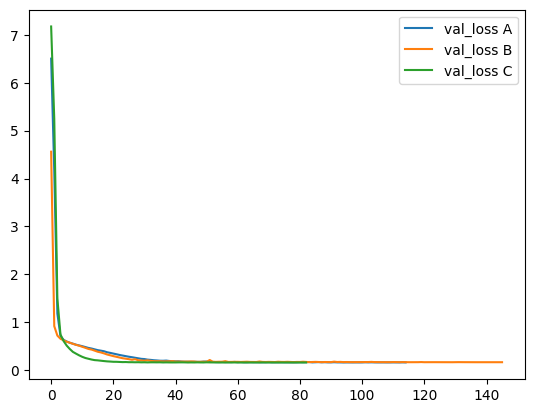

In [ ]:
import matplotlib.pyplot as plt

for v, hist in historiques.items():
    plt.plot(hist.history["val_loss"], label=f"val_loss {v}")
    plt.legend()


In [ ]:
results_mlp = {}

for v, model in models.items():
    y_pred = model.predict(X_test_norm).ravel()

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results_mlp[v] = {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

results_mlp_df = pd.DataFrame(results_mlp).T.sort_values("RMSE")
results_mlp_df

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


,RMSE,MAE,R2
C,0.568781,0.447476,0.178814
A,0.570415,0.446032,0.174089
B,0.571364,0.451494,0.171339


from matplotlib import pyplot as plt
results_mlp_df['RMSE'].plot(kind='hist', bins=20, title='RMSE')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_mlp_df['MAE'].plot(kind='hist', bins=20, title='MAE')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_mlp_df['R2'].plot(kind='hist', bins=20, title='R2')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
results_mlp_df.plot(kind='scatter', x='RMSE', y='MAE', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

... (3 outputs left out)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['RMSE']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'RMSE'}, axis=1)
              .sort_values('RMSE', ascending=True))
  xs = counted['RMSE']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = results_mlp_df.sort_values('RMSE', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('RMSE')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
results_mlp_df['RMSE'].plot(kind='line', figsize=(8, 4), title='RMSE')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
results_mlp_df['MAE'].plot(kind='line', figsize=(8, 4), title='MAE')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
results_mlp_df['R2'].plot(kind='line', figsize=(8, 4), title='R2')
plt.gca().spines[['top', 'right']].set_visible(False)